In [1]:
pip -q install langgraph langchain langchain-core langchain-groq groq

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [2]:
#2) Imports
#Groq SDK: streaming token a token.
#ChatGroq (LangChain): integração com LangGraph.
#LangGraph: grafos + checkpoints + interrupções.
#Também usamos:

#MemorySaver para checkpoints (necessário para breakpoints, interrupções e time travel);
#interrupt e Command para pausar e retomar.

from typing import TypedDict, Literal

from groq import Groq

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

In [3]:
def make_llm(temperature: float = 0.7) -> ChatGroq:
    return ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=temperature,
    )

llm = make_llm()
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001314C3B7080>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001314C634BF0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [4]:
client = Groq()
completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {"role": "system", "content": "Responda em PT-BR, com clareza e didática"},
        {"role": "user", "content": "Explique o que é streaming em LLM e suas utilidades"},
        

            
    ],
    temperature=0.9,
    max_completion_tokens=400,
    top_p=1,
    reasoning_effort="medium",
    stream=True,
)
for chunk in completion:
     print(chunk.choices[0].delta.content or "", end="", flush=True)
print()

## O que é **streaming** em LLMs?

**Streaming** (ou **transmissão**) é a capacidade de uma *Large Language Model* (LLM) enviar a resposta **token por token**, à medida que ela vai sendo gerada, em vez de esperar que todo o texto esteja completo para devolvê‑lo de uma só vez.

Em termos práticos:

| Sem streaming | Com streaming |
|---------------|----------------|
| A API recebe a requisição, gera todo o texto internamente, e só então devolve a resposta completa. | A API devolve o primeiro token logo que ele é produzido, depois o segundo, o terceiro… até terminar. |
| Latência = tempo total de geração + tempo de transmissão. | Latência percebida = tempo até o **primeiro** token (geralmente frações de segundo). |
| O cliente só pode exibir a resposta depois que tudo chega. | O cliente pode mostrar o texto à medida que chega, criando a sensação de “digitação”. |

---

## Como o streaming funciona na prática?

1. **Solicitação com flag de streaming**  
   Na maioria das APIs (OpenAI, Ant

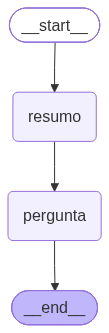

In [5]:
class StudyState(TypedDict, total=False):
    topic: str
    resumo: str
    pergunta: str

def node_resumo(state: StudyState) -> StudyState:
    topic = state.get("topic", "assunto não informado")
    resp = llm.invoke([
        SystemMessage(content="Você cria conteúdo didático em PT-BR."),
        HumanMessage(content=f"Faça um resumo bem curto (6-8 linhas) sobre: {topic}.")
    ])
    return {"resumo": resp.content}

def node_pergunta(state: StudyState) -> StudyState:
    resp = llm.invoke([
        SystemMessage(content="Você cria conteúdo didático em PT-BR."),
        HumanMessage(content=(
            "Crie 1 pergunta conceitual (com resposta curta) baseada no resumo abaixo:\n\n"
            f"{state.get('resumo','')}"
        ))
    ])
    return {"pergunta": resp.content}

builder = StateGraph(StudyState)
builder.add_node("resumo", node_resumo)
builder.add_node("pergunta", node_pergunta)
builder.add_edge(START, "resumo")
builder.add_edge("resumo", "pergunta")
builder.add_edge("pergunta", END)

study_graph = builder.compile()
study_graph


In [6]:
inputs = {"topic": "Breakpoints e depuração no LangGraph"}

for event in study_graph.stream(inputs, stream_mode="updates", ):
    print(event)

{'resumo': {'resumo': '**Breakpoints e depuração no LangGraph**\n\n- Breakpoints são marcadores que você insere nos nós ou nas transições do grafo para interromper a execução e inspecionar o estado interno.  \n- Ao ativar um breakpoint, o motor do LangGraph pausa antes de executar o bloco associado, permitindo observar variáveis, mensagens e contexto.  \n- A interface de depuração oferece visualização em tempo real do fluxo de dados entre nós, facilitando a identificação de lógicas errôneas ou loops infinitos.  \n- Você pode definir breakpoints condicionais, disparando somente quando uma expressão booleana específica for verdadeira.  \n- Durante a pausa, é possível editar valores de entrada ou saída e retomar a execução para testar correções rapidamente.  \n- A combinação de breakpoints com logs estruturados torna a depuração de agentes complexos mais rápida e segura.'}}
{'pergunta': {'pergunta': '**Pergunta:**  \nO que acontece quando um breakpoint é ativado em um nó ou transição do L

In [7]:
for event in study_graph.stream(inputs, stream_mode="values"):
    print(event)

{'topic': 'Breakpoints e depuração no LangGraph'}
{'topic': 'Breakpoints e depuração no LangGraph', 'resumo': '**Breakpoints e depuração no LangGraph**  \n\n- Breakpoints são marcadores inseridos em nós ou fluxos do grafo que pausam a execução, permitindo inspecionar o estado interno (variáveis, contextos e mensagens).  \n- Ao ativar o modo de depuração, o LangGraph exibe um painel interativo onde é possível avançar passo a passo, observar a transição entre nós e visualizar a pilha de chamadas.  \n- É possível definir breakpoints condicionais, disparando a pausa apenas quando uma expressão booleana (ex.: `msg.role == "assistant"`) for verdadeira.  \n- Durante a pausa, o usuário pode modificar valores de contexto ou reexecutar um nó com novos parâmetros, facilitando testes de correção rápida.  \n- Logs detalhados são gerados automaticamente, mostrando entradas, saídas e eventos de roteamento, o que ajuda a rastrear bugs em fluxos complexos.  \n- Ao remover ou desativar os breakpoints, a

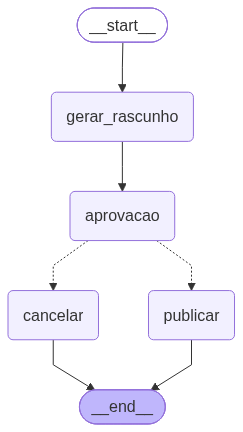

In [8]:
class PublishState(TypedDict, total=False):
    tema: str
    rascunho: str
    aprovado: bool
    publicado: str

def node_gerar_rascunho(state: PublishState) -> PublishState:
    tema = state.get("tema", "tema não informado")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, tom neutro e didático."),
        HumanMessage(content=(
            f"Crie um rascunho curto (máx 12 linhas) de uma prática usada em sobre: {tema}.\n"
            "Inclua: definição, exemplo e um alerta de erro comum."
        ))
    ])
    return {"rascunho": resp.content}

def node_aprovacao(state: PublishState) -> Command[Literal["publicar", "cancelar"]]:
    payload = {
        "pergunta": "Você aprova o rascunho para publicação?",
        "rascunho": state.get("rascunho", "")
    }
    decisao = interrupt(payload)  # PAUSA AQUI

    if decisao is True:
        return Command(goto="publicar", update={"aprovado": True})
    return Command(goto="cancelar", update={"aprovado": False})

def node_publicar(state: PublishState) -> PublishState:
    texto = state.get("rascunho", "")
    return {"publicado": "✅ PUBLICADO (simulação)\n\n" + texto}

def node_cancelar(state: PublishState) -> PublishState:
    return {"publicado": "❌ Cancelado: o rascunho não foi aprovado."}

pub_builder = StateGraph(PublishState)
pub_builder.add_node("gerar_rascunho", node_gerar_rascunho)
pub_builder.add_node("aprovacao", node_aprovacao)
pub_builder.add_node("publicar", node_publicar)
pub_builder.add_node("cancelar", node_cancelar)

pub_builder.add_edge(START, "gerar_rascunho")
pub_builder.add_edge("gerar_rascunho", "aprovacao")
pub_builder.add_edge("publicar", END)
pub_builder.add_edge("cancelar", END)

pub_checkpointer = MemorySaver()
pub_graph = pub_builder.compile(checkpointer=pub_checkpointer)
pub_graph

In [9]:
config = {"configurable": {"thread_id": "pub-01"}}

result = pub_graph.invoke({"tema": "Príncipios básicos da computação quântica"}, config=config)
print("Interrupção recebida:")
print(result.get("__interrupt__"))

Interrupção recebida:
[Interrupt(value={'pergunta': 'Você aprova o rascunho para publicação?', 'rascunho': '**Rascunho – Princípios Básicos da Computação Quântica**  \n\n1. **Definição** – A computação quântica utiliza **qubits**, que podem estar simultaneamente em superposição de 0 e 1, permitindo paralelismo exponencial.  \n2. **Portas quânticas** – Operam em qubits alterando suas amplitudes; as mais comuns são **Hadamard (H)**, **CNOT** e **Pauli‑X**.  \n3. **Exemplo prático** – Prepare um qubit em estado |0⟩, aplique a porta H e, em seguida, meça: o resultado será 0 ou 1 com ≈\u202f50\u202f% de probabilidade cada.  \n4. **Procedimento** –  \n   a) Inicialize o qubit em |0⟩;  \n   b) Execute H usando o simulador (ex.: Qiskit\u202f`qc.h(0)`);  \n   c) Meça (`qc.measure_all()`).  \n5. **Alerta de erro comum** – **Esquecer de inserir a porta de medida**: sem a medição o circuito só produz um vetor de estado, não um resultado clássico, levando a interpretações incorretas dos valores obt

In [10]:
#APROVACAO HUMANA
final = pub_graph.invoke(Command(resume=True), config=config)
print(final["publicado"])

✅ PUBLICADO (simulação)

**Rascunho – Princípios Básicos da Computação Quântica**  

1. **Definição** – A computação quântica utiliza **qubits**, que podem estar simultaneamente em superposição de 0 e 1, permitindo paralelismo exponencial.  
2. **Portas quânticas** – Operam em qubits alterando suas amplitudes; as mais comuns são **Hadamard (H)**, **CNOT** e **Pauli‑X**.  
3. **Exemplo prático** – Prepare um qubit em estado |0⟩, aplique a porta H e, em seguida, meça: o resultado será 0 ou 1 com ≈ 50 % de probabilidade cada.  
4. **Procedimento** –  
   a) Inicialize o qubit em |0⟩;  
   b) Execute H usando o simulador (ex.: Qiskit `qc.h(0)`);  
   c) Meça (`qc.measure_all()`).  
5. **Alerta de erro comum** – **Esquecer de inserir a porta de medida**: sem a medição o circuito só produz um vetor de estado, não um resultado clássico, levando a interpretações incorretas dos valores obtidos.


In [11]:
config2 = {"configurable": {"thread_id": "pub-02"}}

pub_graph.invoke({"tema": "Quando usar ferramentas em agentes"}, config=config2)
final2 = pub_graph.invoke(Command(resume=False), config=config2)
print(final2["publicado"])

❌ Cancelado: o rascunho não foi aprovado.


In [12]:
# 2. Definição do Estado
class PublishState(TypedDict, total=False):
  tema: str
  rascunho: str
  aprovado: bool
  publicado: str


# 3. Nós
def node_gerar_rascunho(state: PublishState) -> PublishState:
  tema = state.get("tema", "tema não informado")
  resp = llm.invoke([
      SystemMessage(content="Escreva em PT-BR, tom neutro e didático e prático, se possível."),
      HumanMessage(
          content=(
              f"Crie um rascunho curto (máx 12 linhas) sobre Computação Quântica"
              f" sobre: {tema}.\nInclua: definição, exemplo e um alerta de erro"
              " comum."
          )
      ),
  ])
  return {"rascunho": resp.content}


def node_aprovacao(state: PublishState) -> Command[Literal["publicar", "cancelar"]]:
  payload = {
      "pergunta": "Você aprova o rascunho para publicação?",
      "rascunho": state.get("rascunho", ""),
  }
  decisao = interrupt(payload)  # PAUSA AQUI

  if decisao is True:
    return Command(goto="publicar", update={"aprovado": True})
  return Command(goto="cancelar", update={"aprovado": False})


def node_publicar(state: PublishState) -> PublishState:
  texto = state.get("rascunho", "")
  return {"publicado": "✅ PUBLICADO (simulação)\n\n" + texto}


def node_cancelar(state: PublishState) -> PublishState:
  return {"publicado": "❌ Cancelado: o rascunho não foi aprovado."}


# 4. Construção e Compilação correta do Grafo
pub_builder = StateGraph(PublishState)
pub_builder.add_node("gerar_rascunho", node_gerar_rascunho)
pub_builder.add_node("aprovacao", node_aprovacao)
pub_builder.add_node("publicar", node_publicar)
pub_builder.add_node("cancelar", node_cancelar)

pub_builder.add_edge(START, "gerar_rascunho")
pub_builder.add_edge("gerar_rascunho", "aprovacao")
pub_builder.add_edge("publicar", END)
pub_builder.add_edge("cancelar", END)

pub_checkpointer = MemorySaver()
pub_graph = pub_builder.compile(checkpointer=pub_checkpointer)

# ==========================================
# COMO EXECUTAR (Lidando com o Interrupt)
# ==========================================
config = {"configurable": {"thread_id": "1"}}

# 1ª Execução: Vai gerar o rascunho e pausar na aprovação
print("--- Iniciando o Grafo ---")
events = pub_graph.stream(
    {"tema": "Computação Quântica"}, config
)
for event in events:
  print(event)

# 2ª Retomada: Enviando a decisão humana (True para aprovar, False para cancelar)
print("\n--- Retomando após a aprovação humana ---")
for event in pub_graph.stream(Command(resume=True), config):
  print(event)

--- Iniciando o Grafo ---
{'gerar_rascunho': {'rascunho': '**Computação Quântica – Rascunho rápido**\n\n1. **Definição** – É um modelo de processamento de informação que usa qubits, que podem estar simultaneamente em múltiplos estados (superposição) e se correlacionar via entrelaçamento.  \n2. **Diferença chave** – Ao contrário dos bits clássicos (0 ou 1), um qubit pode representar 0, 1 ou ambos ao mesmo tempo, permitindo paralelismo exponencial.  \n3. **Exemplo prático** – O algoritmo de Shor fatoriza números inteiros grandes em tempo polinomial, ameaçando a criptografia RSA baseada em fatoração difícil.  \n4. **Aplicação emergente** – Simulação de moléculas para descoberta de novos fármacos, onde a química quântica clássica seria inviável.  \n5. **Hardware típico** – Processadores baseados em íons aprisionados, supercondutores ou fotões.  \n6. **Alerta de erro comum** – Ignorar o **decoerência**: qubits perdem sua coerência rapidamente ao interagir com o ambiente, levando a resultado

In [13]:
config = {"configurable": {"thread_id": "pub-01"}}

result = pub_graph.invoke({"tema": "Princípios da Computação Quântica"}, config=config)
print("Interrupção recebida:")
print(result.get("__interrupt__"))

Interrupção recebida:
[Interrupt(value={'pergunta': 'Você aprova o rascunho para publicação?', 'rascunho': '**Princípios da Computação Quântica – Rascunho**\n\n1. **Definição:** A computação quântica utiliza qubits, que podem estar simultaneamente em superposição de 0 e 1, e explorar o entrelaçamento para processar informações de forma paralela e não clássica.  \n2. **Superposição:** Um qubit em estado \\|ψ⟩ = α\\|0⟩ + β\\|1⟩ representa todas as combinações possíveis, permitindo que algoritmos explorem um espaço de soluções exponencialmente maior.  \n3. **Entrelaçamento:** Qubits entrelaçados apresentam correlações instantâneas; medir um afeta o estado do outro, mesmo a grandes distâncias, ampliando o poder computacional.  \n4. **Portas quânticas:** Operações unitárias (ex.: Hadamard, CNOT) manipulam a fase e a amplitude dos qubits sem perder coerência.  \n5. **Exemplo prático:** O algoritmo de Shor usa superposição e entrelaçamento para fatorar números grandes em tempo polinomial, alg

In [14]:
#B3) Retomando com rejeição (resume=False)


In [15]:
config2 = {"configurable": {"thread_id": "pub-02"}}

pub_graph.invoke({"tema": "Quando usar ferramentas em agentes"}, config=config2)
final2 = pub_graph.invoke(Command(resume=False), config=config2)
print(final2["publicado"])

❌ Cancelado: o rascunho não foi aprovado.


In [16]:
config2 = {"configurable": {"thread_id": "pub-02"}}

pub_graph.invoke({"tema": "Quais seus principais usos da Computação Quântica"}, config=config2)
final2 = pub_graph.invoke(Command(resume=True), config=config2)
print(final2["publicado"])

✅ PUBLICADO (simulação)

**Computação Quântica – Uso e Cuidados**  

1. **Definição:** Tecnologia que utiliza qubits e princípios de superposição e emaranhamento para processar informações de forma exponencialmente mais rápida que bits clássicos.  
2. **Criptografia:** Algoritmos como Shor quebram RSA e ECC, exigindo novos padrões de criptografia pós‑quântica.  
3. **Otimização:** Problemas de roteamento, logística e finanças (ex.: algoritmo QAOA) são resolvidos com menos iterações.  
4. **Simulação de materiais:** Modelagem de interações moleculares para desenvolvimento de fármacos e novos materiais.  
5. **Aprendizado de máquina:** Quantum‑SVM e redes quânticas aceleram treinamento em conjuntos de dados complexos.  
6. **Exemplo prático:** Um chip de 127 qubits da IBM demonstrou vantagem quântica ao otimizar um problema de Max‑Cut em poucos minutos, enquanto o melhor algoritmo clássico levou horas.  
7. **Alerta de erro comum:** Ignorar o ruído quântico e a necessidade de correção de

In [17]:
#PARTE C: Breakpoints (estaticos)

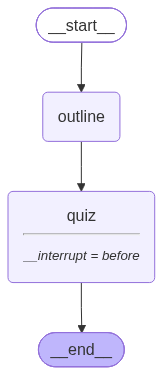

In [18]:
class DebugState(TypedDict, total=False):
    assunto: str
    outline: str
    quiz: str

def node_outline(state: DebugState) -> DebugState:
    assunto = state.get("assunto", "assunto")
    resp = llm.invoke([
        SystemMessage(content="Crie conteúdo em PT-BR, objetivo."),
        HumanMessage(content=f"Crie um outline com 4 tópicos sobre: {assunto}.")
    ])
    return {"outline": resp.content}

def node_quiz(state: DebugState) -> DebugState:
    resp = llm.invoke([
        SystemMessage(content="Crie conteúdo em PT-BR, objetivo."),
        HumanMessage(content=(
            "Crie 2 perguntas de múltipla escolha baseadas no outline abaixo:\n\n"
            f"{state.get('outline','')}\n\n"
            "Não precisa gabarito."
        ))
    ])
    return {"quiz": resp.content}

dbg_builder = StateGraph(DebugState)
dbg_builder.add_node("outline", node_outline)
dbg_builder.add_node("quiz", node_quiz)
dbg_builder.add_edge(START, "outline")
dbg_builder.add_edge("outline", "quiz")
dbg_builder.add_edge("quiz", END)

dbg_checkpointer = MemorySaver()
dbg_graph = dbg_builder.compile(checkpointer=dbg_checkpointer, interrupt_before=["quiz"])
dbg_graph

In [19]:
dbg_config = {"configurable": {"thread_id": "dbg-01"}}

partial = dbg_graph.invoke({"assunto": "Computação Quântica"}, config=dbg_config)
print("Parou no breakpoint. Estado parcial:")
print(partial)

print("\nContinuando...")
complete = dbg_graph.invoke(None, config=dbg_config)
print("\nEstado final:")
print(complete)

Parou no breakpoint. Estado parcial:
{'assunto': 'Computação Quântica', 'outline': '**Outline: Computação Quântica**\n\n1. **Fundamentos da mecânica quântica aplicados à computação**\n   - Qubits: superposição e entrelaçamento  \n   - Portas lógicas quânticas (Hadamard, CNOT, etc.)  \n   - Medição e colapso de estado  \n\n2. **Arquiteturas e tecnologias de hardware quântico**\n   - Qubits baseados em íons aprisionados, supercondutores, fotônicos e pontos quânticos  \n   - Controle de coerência e correção de erros quânticos  \n   - Escalabilidade e desafios de temperatura/isolamento  \n\n3. **Algoritmos quânticos e vantagens computacionais**\n   - Algoritmo de Shor (fatoração) e implicações em criptografia  \n   - Algoritmo de Grover (busca não estruturada)  \n   - Simulação de sistemas físicos/químicos e otimização combinatória  \n\n4. **Impactos, aplicações e perspectivas de mercado**\n   - Criptografia pós‑quântica e segurança da informação  \n   - Descoberta de materiais, química co

In [20]:
#Parte D — Breakpoints dinâmicos

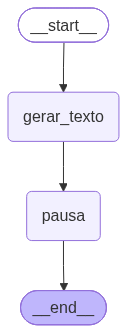

In [21]:
class DynBPState(TypedDict, total=False):
    tema: str
    texto: str
    modo_debug: bool

def node_gerar_texto(state: DynBPState) -> DynBPState:
    tema = state.get("tema", "tema")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR."),
        HumanMessage(content=f"Escreva uma explicação em até 10 linhas sobre: {tema}.")
    ])
    return {"texto": resp.content}

def node_pausa_condicional(state: DynBPState) -> DynBPState:
    if state.get("modo_debug"):
        interrupt({
            "motivo": "modo_debug ligado",
            "amostra_texto": state.get("texto", "")[:250]
        })
        return {}

    # Heurística extra: se ficar muito grande, também pausa
    if len(state.get("texto", "")) > 900:
        interrupt({"motivo": "texto longo demais", "tamanho": len(state.get("texto",""))})
    return {}

dyn_builder = StateGraph(DynBPState)
dyn_builder.add_node("gerar_texto", node_gerar_texto)
dyn_builder.add_node("pausa", node_pausa_condicional)
dyn_builder.add_edge(START, "gerar_texto")
dyn_builder.add_edge("gerar_texto", "pausa")
dyn_builder.add_edge("pausa", END)

dyn_checkpointer = MemorySaver()
dyn_graph = dyn_builder.compile(checkpointer=dyn_checkpointer)
dyn_graph

In [22]:
#D1) Sem pausa (modo_debug=False)
cfg = {"configurable": {"thread_id": "dyn-01"}}
res = dyn_graph.invoke({"tema": "Quais são as próximas evoluções da computação quântica?", "modo_debug": False}, config=cfg)
print("OK. Não pausou.\n")
print(res["texto"][:500], "...")

OK. Não pausou.

**Próximas evoluções da computação quântica (até 10 linhas)**  

1. **Qubits mais estáveis** – desenvolvimento de materiais e técnicas de controle que aumentam o tempo de coerência, reduzindo erros de decoerência.  
2. **Correção de erros quânticos** – implementação prática de códigos de correção (por exemplo, surface codes) para tornar os processadores tolerantes a falhas.  
3. **Escalabilidade modular** – arquiteturas que conectam múltiplos chips quânticos via redes fotônicas ou de spin, permi ...


In [23]:
#D2) Com pausa (modo_debug=True) e retomada
cfg2 = {"configurable": {"thread_id": "dyn-02"}}
res2 = dyn_graph.invoke({"tema": "Ciência básica da computação quântica", "modo_debug": True}, config=cfg2)

print("Pausou? Payload:")
print(res2.get("__interrupt__"))

print("\nRetomando...")
res2b = dyn_graph.invoke(Command(resume="seguir"), config=cfg2)
print("Concluiu. Texto (amostra):")
print(res2b["texto"][:350], "...")

Pausou? Payload:
[Interrupt(value={'motivo': 'modo_debug ligado', 'amostra_texto': 'A computação quântica estuda algoritmos que utilizam **qubits**, unidades de informação que podem estar simultaneamente em múltiplos estados graças ao princípio da **superposição**.  \nAlém da superposição, os qubits podem ser **entrelaçados** (entang'}, id='7421ea214e7075f15550b33ee996ba8e', response_schema=None)]

Retomando...
Concluiu. Texto (amostra):
A computação quântica estuda algoritmos que utilizam **qubits**, unidades de informação que podem estar simultaneamente em múltiplos estados graças ao princípio da **superposição**.  
Além da superposição, os qubits podem ser **entrelaçados** (entanglement), permitindo correlações instantâneas que não existem na computação clássica.  
Essas proprie ...


In [24]:
#Parte E — Editando o estado (feedback humano)

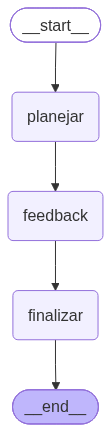

In [25]:
class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    versao_final: str

def node_planejar(state: FeedbackState) -> FeedbackState:
    tema = state.get("tema", "tema")
    nivel = state.get("nivel", "iniciante")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem prático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos para idéias de criações de Startups {tema}. "
            f"Nível: {nivel}. Inclua 1 exemplo prático."
        ))
    ])
    return {"roteiro": resp.content}

def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    ajuste = interrupt({
        "pergunta": "Deseja ajustar o nível? (iniciante/intermediário/avançado) ou deixe em branco para manter.",
        "nivel_atual": state.get("nivel", "iniciante")
    })
    if isinstance(ajuste, str) and ajuste.strip():
        return {"nivel": ajuste.strip()}
    return {}

def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, com estrutura para apostila."),
        HumanMessage(content=(
            "Transforme o roteiro abaixo em uma versão final formatada:\n\n"
            f"TEMA: {state.get('tema')}\n"
            f"NÍVEL: {state.get('nivel')}\n\n"
            f"ROTEIRO:\n{state.get('roteiro','')}\n\n"
            "Inclua uma seção final: 'Erros comuns' com 3 itens."
        ))
    ])
    return {"versao_final": resp.content}

fb_builder = StateGraph(FeedbackState)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "planejar")
fb_builder.add_edge("planejar", "feedback")
fb_builder.add_edge("feedback", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [26]:
#E1) Rodar até o feedback (interrupt)

In [27]:
fb_config = {"configurable": {"thread_id": "fb-01"}}

part = fb_graph.invoke({"tema": "Ideias de Startups", "nivel": "iniciante"}, config=fb_config)
print("Payload do interrupt:")
print(part.get("__interrupt__"))

Payload do interrupt:
[Interrupt(value={'pergunta': 'Deseja ajustar o nível? (iniciante/intermediário/avançado) ou deixe em branco para manter.', 'nivel_atual': 'iniciante'}, id='435452e8093a697dc681264cafeea2a5', response_schema=None)]


In [28]:
#E2) Retomar via resume (ex.: mudar para intermediário)

In [29]:
final_fb = fb_graph.invoke(Command(resume="avançado"), config=fb_config)
print("Nível final:", final_fb.get("nivel"))
print(final_fb["versao_final"][:700], "...")

Nível final: avançado
# Apostila – Ideias de Startups  
**Nível:** Avançado | **Objetivo:** Transformar uma ideia em um modelo de negócio validado  

---

## Sumário  

1. [Introdução](#introdução)  
2. [Os 5 passos essenciais](#os-5-passos-essenciais)  
   - 2.1 [Identifique uma dor real](#1-identifique-uma-dor-real)  
   - 2.2 [Defina o público‑alvo](#2-defina-o-público‑alvo)  
   - 2.3 [Proponha uma solução mínima (MVP)](#3-proponha-uma-solução‑mínima-mvp)  
   - 2.4 [Valide o interesse](#4-valide-o‑interesse)  
   - 2.5 [Planeje os próximos passos](#5-planeje-os‑próximos‑passos)  
3. [Exemplo prático: Entrega de Alimentos Saudáveis para Empresas](#exemplo-prático-entrega-de-alimentos-saudáveis-para-empresas)  ...


In [30]:
#E3) Editar o estado via update_state e continuar

In [31]:
fb_config2 = {"configurable": {"thread_id": "fb-02"}}

# 1) para no feedback
fb_graph.invoke({"tema": "Breakpoints dinâmicos", "nivel": "iniciante"}, config=fb_config2)

# 2) mostra o estado atual
state_now = fb_graph.get_state(fb_config2)
print("Estado antes da edição:")
print(state_now.values)

# 3) atualiza o estado (correção humana)
new_cfg = fb_graph.update_state(
    fb_config2,
    values={"nivel": "avançado", "tema": "Breakpoints dinâmicos (com casos reais)"}
)

print("\nConfig retornado por update_state:", new_cfg)

# 4) continua a execução
cfg_to_use = new_cfg if new_cfg is not None else fb_config2
done = fb_graph.invoke(None, config=cfg_to_use)

print("\nEstado final (amostra):")
print("tema:", done.get("tema"))
print("nivel:", done.get("nivel"))
print(done.get("versao_final", "")[:700], "...")

Estado antes da edição:
{'tema': 'Breakpoints dinâmicos', 'nivel': 'iniciante', 'roteiro': '**Roteiro de 5\u202ftópicos para gerar ideias de startups com *breakpoints\u202fdinâmicos***  \n*(Nível iniciante – linguagem prática e direta)*  \n\n---\n\n## 1️⃣ Identifique um problema que muda de comportamento com a escala  \n- **O que observar:** situações em que a necessidade do cliente ou a eficiência do processo varia drasticamente quando algum indicador (número de usuários, volume de dados, frequência de uso, etc.) ultrapassa um determinado ponto.  \n- **Perguntas‑chave:**  \n  - O que acontece quando a demanda dobra?  \n  - Existe um “gargalo” que só aparece após X\u202fmil usuários?  \n  - Como o custo ou a experiência muda antes e depois desse ponto?  \n\n## 2️⃣ Defina o *breakpoint* (ponto de ruptura) e a métrica de monitoramento  \n- Escolha **uma métrica mensurável** (ex.: transações por segundo, GB armazenados, churn rate).  \n- Estime **onde** a métrica deixa de ser sustentável 

In [32]:
#Parte F — Time travel (viagem no tempo)
#listar checkpoints;
#voltar a um checkpoint antigo;
#alterar o estado naquele ponto;
#e continuar gerando um novo futuro (fork).

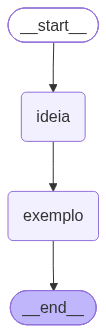

In [33]:
class TravelState(TypedDict, total=False):
    ideia: str
    exemplo: str

def node_ideia(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content="Gere uma ideia de uso (1 frase) para usar LangGraph em uma Startup de IA.")
    ])
    return {"ideia": resp.content.strip()}

def node_exemplo(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content=(
            "Crie um exemplo prático modelo de Startups de IA, de acordo com a ideia abaixo.\n"
            f"IDEIA: {state.get('ideia','')}\n"
            "Formato: 6-10 linhas, com bullets."
        ))
    ])
    return {"exemplo": resp.content}

travel_builder = StateGraph(TravelState)
travel_builder.add_node("ideia", node_ideia)
travel_builder.add_node("exemplo", node_exemplo)
travel_builder.add_edge(START, "ideia")
travel_builder.add_edge("ideia", "exemplo")
travel_builder.add_edge("exemplo", END)

travel_checkpointer = MemorySaver()
travel_graph = travel_builder.compile(checkpointer=travel_checkpointer)
travel_graph

In [34]:
#F1) Execução normal

In [35]:
t_cfg = {"configurable": {"thread_id": "travel-01"}}

original = travel_graph.invoke({}, config=t_cfg)
print("IDEIA ORIGINAL:", original.get("ideia"))
print("\nEXEMPLO ORIGINAL:\n", original.get("exemplo"))

IDEIA ORIGINAL: Use o LangGraph para criar fluxos dinâmicos que personalizam respostas de chatbots de IA em tempo real, adaptando a conversa ao contexto e ao histórico do usuário.

EXEMPLO ORIGINAL:
 - **Nome:** ConversaFlex  
- **Problema:** Chatbots genéricos não retêm contexto nem aprendem com interações passadas, gerando respostas incoerentes.  
- **Solução:** Plataforma SaaS que usa LangGraph para montar fluxos de diálogo dinâmicos, personalizando respostas em tempo real com base no histórico e no contexto do usuário.  
- **Tecnologia:** LangGraph + LLMs (OpenAI, Anthropic), banco de dados vetorial para memória de longo prazo, API REST para integração fácil.  
- **Modelo de Receita:** Plano por número de sessões mensais + cobrança por armazenamento de histórico avançado.  
- **Go‑to‑Market:** Parcerias com e‑commerces e serviços de suporte ao cliente; trial de 30 dias com integração via webhook.  
- **Métricas-Chave:** Taxa de retenção de usuários (≥85%), redução do tempo de resol

In [36]:
history = list(travel_graph.get_state_history(t_cfg))
print("Quantidade de checkpoints:", len(history))

for i, st in enumerate(history[:6]):
    checkpoint_id = st.config["configurable"].get("checkpoint_id")
    print(f"{i}: next={st.next} | checkpoint_id={checkpoint_id} | keys={list(st.values.keys())}")

Quantidade de checkpoints: 4
0: next=() | checkpoint_id=1f1d7dc8-ac41-62d6-8002-2f7c06c4e7ec | keys=['ideia', 'exemplo']
1: next=('exemplo',) | checkpoint_id=1f1d7dc8-a1a7-6bf4-8001-18b828f3b9e1 | keys=['ideia']
2: next=('ideia',) | checkpoint_id=1f1d7dc8-9b4b-67e3-8000-28cf52b82ea6 | keys=[]
3: next=('__start__',) | checkpoint_id=1f1d7dc8-9b4b-67e2-bfff-162085a96659 | keys=[]


In [37]:
#F3) Fork: alterando o passado e criando novo futuro
#Dica: normalmente history[1] é um ponto anterior ao último nó (dependendo da versão).

In [38]:
selected = history[1]  # ajuste se necessário
print("Selecionado next:", selected.next)
print("Values naquele ponto:", selected.values)

new_config = travel_graph.update_state(
    selected.config,
    values={"ideia": "Listar projetos reais de SLMs para uso empresarial"}
)

cfg_to_use = new_config if new_config is not None else selected.config
fork = travel_graph.invoke(None, config=cfg_to_use)

print("\n--- FUTURO (FORK) ---")
print("IDEIA:", fork.get("ideia"))
print("EXEMPLO:\n", fork.get("exemplo"))

Selecionado next: ('exemplo',)
Values naquele ponto: {'ideia': 'Use o LangGraph para criar fluxos dinâmicos que personalizam respostas de chatbots de IA em tempo real, adaptando a conversa ao contexto e ao histórico do usuário.'}

--- FUTURO (FORK) ---
IDEIA: Listar projetos reais de SLMs para uso empresarial
EXEMPLO:
 - **Nome:** IA BizModels – Plataforma de curadoria de SLMs (Specialized Language Models) para empresas.  
- **Missão:** Facilitar a adoção de modelos de linguagem especializados, listando projetos reais, casos de uso e métricas de desempenho.  
- **Produto:** Dashboard com filtros por setor, volume de dados, custo de inferência e compliance, permitindo download de pipelines prontos.  
- **Modelo de receita:** SaaS por assinatura (planos mensais/anuais) + comissão sobre integrações de parceiros de cloud.  
- **Tecnologia:** Backend em Python/FastAPI, banco Neo4j para grafos de projetos, UI React + D3.js para visualizações interativas.  
- **Mercado‑alvo:** Médias e grande

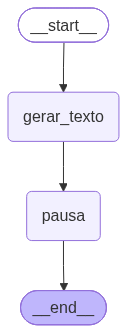

In [48]:
import re

PALAVRAS_CHAVE = {"Startups", "IA", "LAnggraph"}

def node_gerar_texto(state: DynBPState) -> DynBPState:
    tema = state.get("tema", "tema")
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR."),
        HumanMessage(content=f"Escreva um texto com poucas palavras sobre os temas em bulletpoints {tema}.")
    ])
    return {"texto": resp.content}

def node_pausa_condicional(state: DynBPState) -> DynBPState:
    texto = state.get("texto", "")

    if state.get("modo_debug"):
        interrupt({
            "motivo": "modo_debug ligado",
            "amostra_texto": texto[:250],
        })
        return {}

    palavras = set(re.findall(r"\w+", texto.casefold()))
    encontradas = sorted(PALAVRAS_CHAVE & palavras)

    if encontradas:
        interrupt({
            "motivo": "palavras-chave detectadas",
            "palavras_encontradas": encontradas,
            "amostra_texto": texto[:250],
        })

    return {}
dyn_builder = StateGraph(DynBPState)
dyn_builder.add_node("gerar_texto", node_gerar_texto)
dyn_builder.add_node("pausa", node_pausa_condicional)
dyn_builder.add_edge(START, "gerar_texto")
dyn_builder.add_edge("gerar_texto", "pausa")
dyn_builder.add_edge("pausa", END)

dyn_checkpointer = MemorySaver()
dyn_graph = dyn_builder.compile(checkpointer=dyn_checkpointer)
dyn_graph

In [49]:
cfg2 = {"configurable": {"thread_id": "dyn-02"}}
res2 = dyn_graph.invoke({"tema": "Startups, IA, Langgraph", "modo_debug": True}, config=cfg2)

res2b = dyn_graph.invoke(Command(resume="seguir"), config=cfg2)
print("Concluiu. Texto (amostra):")
print(res2b["texto"][:450], "...")

Concluiu. Texto (amostra):
- **Startups**: empresas ágeis que transformam ideias inovadoras em soluções de mercado, impulsionadas por tecnologia e cultura de experimentação.  
- **IA (Inteligência Artificial)**: motores de aprendizado que automatizam decisões, otimizam processos e criam novas oportunidades de negócio.  
- **LangGraph**: framework para construir fluxos de linguagem natural, facilitando a integração de modelos de IA em aplicativos de forma modular e escaláve ...


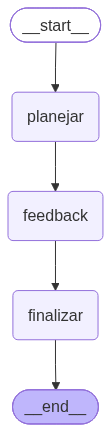

In [50]:
class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    pedido: str
    versao_final: str


def node_planejar(state: FeedbackState) -> FeedbackState:
    tema = state.get("tema", "tema")
    nivel = state.get("nivel", "iniciante")

    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem didático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos para uma aula sobre {tema}. "
            f"Nível: {nivel}. Inclua 1 exemplo prático."
        )),
    ])
    return {"roteiro": resp.content}


def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    novo_nivel = interrupt({
        "pergunta": (
            "Qual nível deseja? iniciante/intermediário/avançado. "
            "Deixe em branco para manter."
        ),
        "nivel_atual": state.get("nivel", "iniciante"),
    })

    nivel = state.get("nivel", "iniciante")
    if isinstance(novo_nivel, str) and novo_nivel.strip():
        nivel = novo_nivel.strip()

    tema = state.get("tema", "tema")

    while True:
        novo_tema = interrupt({
            "pergunta": "Qual tema deseja? Deixe em branco para manter.",
            "tema_atual": tema,
        })

        if isinstance(novo_tema, str) and novo_tema.strip():
            tema = novo_tema.strip()

        confirmacao = interrupt({
            "pergunta": f"Tem certeza do tema '{tema}'? Responda yes ou no.",
            "tema": tema,
        })

        while str(confirmacao).strip().casefold() not in {"yes", "no"}:
            confirmacao = interrupt({
                "pergunta": "Resposta inválida. Responda yes ou no.",
                "tema": tema,
            })

        if str(confirmacao).strip().casefold() == "yes":
            return {"nivel": nivel, "tema": tema}


def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(
            content="Escreva em PT-BR, com estrutura para apostila."
        ),
        HumanMessage(content=(
            "Transforme o roteiro abaixo em uma versão final formatada.\n"
            "Adapte o conteúdo ao nível informado e atenda ao pedido "
            "adicional do humano.\n\n"
            f"TEMA: {state.get('tema')}\n"
            f"NÍVEL: {state.get('nivel')}\n\n"
            f"ROTEIRO:\n{state.get('roteiro', '')}\n\n"
            f"PEDIDO ADICIONAL: {state.get('pedido') or 'Nenhum.'}\n\n"
            "Inclua uma seção final: 'Erros comuns' com 3 itens."
        )),
    ])
    return {"versao_final": resp.content}


fb_builder = StateGraph(FeedbackState)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "planejar")
fb_builder.add_edge("planejar", "feedback")
fb_builder.add_edge("feedback", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [51]:
fb_config = {"configurable": {"thread_id": "fb-tres-nos-01"}}

parcial = fb_graph.invoke(
    {"tema": "Streaming no LangGraph", "nivel": "iniciante"},
    config=fb_config,
)
print(parcial.get("__interrupt__"))

[Interrupt(value={'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_atual': 'iniciante'}, id='a4e7f8c914ff3d0916d4f5832936f55c', response_schema=None)]


In [52]:
final_fb = fb_graph.invoke(Command(resume="avançado"), config=fb_config)
print("Nível atualizado:", final_fb.get("nivel"))
print("Payload do interrupt:")
print(part.get("__interrupt__"))

Nível atualizado: iniciante
Payload do interrupt:
[Interrupt(value={'pergunta': 'Deseja ajustar o nível? (iniciante/intermediário/avançado) ou deixe em branco para manter.', 'nivel_atual': 'iniciante'}, id='435452e8093a697dc681264cafeea2a5', response_schema=None)]


In [53]:
parcial = fb_graph.invoke(
    Command(resume="Computação Quântica em processamentos comparados com GPU"),
    config=fb_config,
)
print("Payload do interrupt:")
print(parcial.get("__interrupt__"))


Payload do interrupt:
[Interrupt(value={'pergunta': "Tem certeza do tema 'Computação Quântica em processamentos comparados com GPU'? Responda yes ou no.", 'tema': 'Computação Quântica em processamentos comparados com GPU'}, id='a4e7f8c914ff3d0916d4f5832936f55c', response_schema=None)]


In [54]:
# Confirma o tema e gera o material.
final = fb_graph.invoke(
    Command(resume="yes"),
    config=fb_config,
)
print("Nível:", final["nivel"])
print("Tema:", final["tema"])
print(final["versao_final"])

Nível: avançado
Tema: Computação Quântica em processamentos comparados com GPU
# **Apostila – Streaming em LangGraph**  
**Nível:** Avançado  
**Duração sugerida:** 45 – 60 min  

> **Objetivo:** Capacitar o estudante a projetar, implementar e otimizar fluxos de geração de texto *streaming* usando a biblioteca **LangGraph**, integrando‑o a servidores assíncronos (FastAPI, WebSocket, SSE) e preparando‑o para ambientes de produção de alta escala.  

---  

## Sumário  

1. [Introdução ao Streaming](/#1-introdução-ao-streaming)  
2. [Arquitetura LangGraph para Streaming](/#2-arquitetura-langgraph-para-streaming)  
3. [Implementação avançada](/#3-implementação-avançada)  
4. [Integração com FastAPI + SSE](/#4-integração-com-fastapi‑sse)  
5. [Performance, escalabilidade e paralelismo](/#5-performance‑escalabilidade‑e‑paralelismo)  
6. [Boas práticas de produção](/#6-boas-práticas-de‑produção)  
7. [Erros comuns](/#7-erros‑comuns)  
8. [Exercícios](/#8-exercícios)  
9. [Referências](/#9-ref

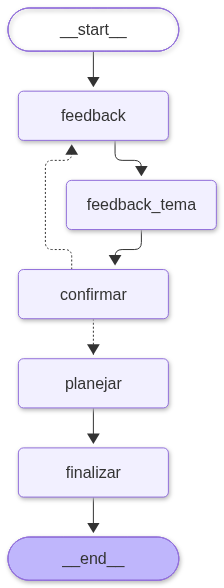

In [55]:
from typing import TypedDict, Literal

from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command


class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    versao_final: str

def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": (
            "Qual nível deseja? iniciante/intermediário/avançado. "
            "Deixe em branco para manter."
        ),
        "nivel_atual": state.get("nivel", "iniciante"),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"nivel": resposta.strip()}

    return {}


def node_feedback_tema(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": "Deseja mudar de tema? Deixe em branco para manter.",
        "tema_atual": state.get("tema", ""),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"tema": resposta.strip()}

    return {}
    
def node_planejar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem didático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos sobre {state.get('tema', 'LangGraph')}. "
            f"Nível: {state.get('nivel', 'iniciante')}. "
            "Inclua 1 exemplo prático."
        )),
    ])
    return {"roteiro": resp.content}

def node_confirmar(
    state: FeedbackState,
) -> Command[Literal["planejar", "feedback"]]:
    pergunta = {
        "pergunta": (
            "Confirma o tema e o nível? "
            "Responda yes para gerar o material ou no para editar novamente."
        ),
        "tema": state.get("tema", ""),
        "nivel": state.get("nivel", "iniciante"),
    }

    resposta = interrupt(pergunta)

    while str(resposta).strip().casefold() not in {"yes", "no"}:
        resposta = interrupt({
            **pergunta,
            "erro": "Resposta inválida. Digite yes ou no.",
        })

    if str(resposta).strip().casefold() == "yes":
        return Command(goto="planejar")

    return Command(goto="feedback")

def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, com estrutura para apostila."),
        HumanMessage(content=(
            "Transforme o roteiro em uma versão final formatada.\n\n"
            f"TEMA: {state.get('tema', '')}\n"
            f"NÍVEL: {state.get('nivel', 'iniciante')}\n"
            f"ROTEIRO:\n{state.get('roteiro', '')}\n\n"
            "Inclua uma seção 'Erros comuns' com 3 itens."
        )),
    ])
    return {"versao_final": resp.content}


fb_builder = StateGraph(FeedbackState)

fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("feedback_tema", node_feedback_tema)
fb_builder.add_node("confirmar", node_confirmar)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "feedback")
fb_builder.add_edge("feedback", "feedback_tema")
fb_builder.add_edge("feedback_tema", "confirmar")
fb_builder.add_edge("planejar", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [56]:
fb_config = {"configurable": {"thread_id": "fb-confirmacao-01"}}

resultado = fb_graph.invoke(
    {"tema": "LangGraph", "nivel": "iniciante"},
    config=fb_config,
)

while resultado.get("__interrupt__"):
    pausa = resultado["__interrupt__"][0]

    for chave, valor in pausa.value.items():
        print(f"{chave}: {valor}")

    resposta = input("\nSua resposta: ")

    resultado = fb_graph.invoke(
        Command(resume=resposta),
        config=fb_config,
    )

from IPython.display import clear_output, display, Markdown

clear_output(wait=True)

print("Nível:", resultado["nivel"])
print("Tema:", resultado["tema"])

display(Markdown(resultado["versao_final"]))

Nível: avançado
Tema: Computação Quântica


# **Apostila – Computação Quântica (Nível Avançado)**  

> **Objetivo:** Capacitar o estudante avançado a compreender os fundamentos teóricos, algoritmos de vantagem, modelos de hardware, técnicas de correção de erros e a implementar um caso prático (VQE para H₂) usando as principais ferramentas de software quântico.  

---  

## Sumário  

1. [Fundamentos Teóricos da Mecânica Quântica Aplicados à Computação](#1-fundamentos-teóricos)  
2. [Algoritmos Quânticos de Complexidade Superior](#2-algoritmos-quânticos)  
3. [Modelos de Computação Quântica e Arquiteturas Físicas](#3-modelos-e-arquiteturas)  
4. [Correção de Erros Quânticos e Tolerância a Falhas](#4-correção-de-erros)  
5. [Exemplo Prático – Simulação da Energia da Molécula H₂ com VQE](#5-exemplo-prático)  
6. [Erros Comuns](#6-erros-comuns)  
7. [Referências Bibliográficas](#7-referências)  

---  

<a name="1-fundamentos-teóricos"></a>  

## 1. Fundamentos Teóricos da Mecânica Quântica Aplicados à Computação  

| Tópico | Conteúdo | Comentário Pedagógico |
|--------|----------|-----------------------|
| **Postulados da mecânica quântica** | • Estado quântico  <br>• Evolução unitária  <br>• Medida (colapso) | O aluno deve escrever o vetor de estado \(|\psi\rangle\) e aplicar a evolução \(U|\psi\rangle\). |
| **Qubit** | \(|\psi\rangle = \alpha|0\rangle + \beta|1\rangle,\;\; |\alpha|^{2}+|\beta|^{2}=1\) | Representação em notação bra‑ket e como vetor coluna \(\begin{bmatrix}\alpha\\\beta\end{bmatrix}\). |
| **Superposição & Entrelaçamento** | • Superposição → paralelismo exponencial <br>• Entanglement → correlação não‑clássica (ex.: Bell state \(\frac{|00\rangle+|11\rangle}{\sqrt2}\)) | Exercício: montar o estado de *n* qubits usando produto tensorial \(\bigotimes_{i=1}^{n}|\psi_i\rangle\). |
| **Operadores lineares e portas quânticas** | Matriz unitária \(U^\dagger U = I\). Exemplos: <br>• Pauli‑X  \(\begin{pmatrix}0&1\\1&0\end{pmatrix}\) <br>• Hadamard \(H\) <br>• CNOT, S, T | Mostrar a composição de portas como multiplicação de matrizes. |
| **Circuitos quânticos** | Diagrama de portas, profundidade (circuit depth) e largura (número de qubits). | **Objetivo:** desenhar circuitos simples e calcular a profundidade total. |

### Exercício‑Objetivo  
> **Escreva** o vetor de estado de um sistema de 3 qubits \(|\psi\rangle = |+\rangle\otimes|0\rangle\otimes|1\rangle\) e **aplique** a sequência de portas \((H\otimes I\otimes I)\;\rightarrow\;(CNOT_{12})\;\rightarrow\;(T\otimes I\otimes I)\).  

---  

<a name="2-algoritmos-quânticos"></a>  

## 2. Algoritmos Quânticos de Complexidade Superior  

| Algoritmo | Problema Resolvido | Complexidade Clássica | Complexidade Quântica |
|-----------|-------------------|----------------------|-----------------------|
| **Shor** | Fatoração de inteiros | \(O\!\big(e^{(\log N)^{1/3}(\log\log N)^{2/3}}\big)\) (sub‑exponencial) | \(O\!\big((\log N)^{3}\big)\) |
| **Grover** | Busca não estruturada | \(O(N)\) | \(O(\sqrt{N})\) |
| **Quantum Phase Estimation (QPE)** | Estimação de fase de um operador unitário | — | \(O(1/\epsilon)\) |
| **Variational Quantum Eigensolver (VQE)** | Estado fundamental de Hamiltonianos | Diagonalização exata → exponencial | Polinomial no número de parâmetros variacionais |

### 2.1. Análise de Complexidade  

* **Amplitude Amplification (Grover):** Cada iteração quadruplica a probabilidade de encontrar a solução correta.  
* **Quantum Fourier Transform (QFT) (Shor):** Implementado em \(O((\log N)^2)\) portas, permite a extração de fatores por análise de período.  

### 2.2. Limitações Inferiores  

* **Teorema de Bennett et al. (1997):** Qualquer algoritmo quântico que resolve a busca não estruturada requer \(\Omega(\sqrt{N})\) consultas – prova de optimalidade de Grover.  

---  

<a name="3-modelos-e-arquiteturas"></a>  

## 3. Modelos de Computação Quântica e Arquiteturas Físicas  

### 3.1. Modelos de Computação  

| Modelo | Princípio | Principais Ferramentas |
|--------|-----------|------------------------|
| **Gate Model (circuitos)** | Operações discretas unitárias | Qiskit, Cirq, Braket |
| **Adiabático / Quantum Annealing** | Evolução lenta de Hamiltoniano \(H(t)\) de \(H_0\) a \(H_P\) | D‑Wave Ocean SDK |
| **Measurement‑Based Quantum Computing (MBQC)** | Computação por medições adaptativas em estado de cluster 2‑D | PyZX, ProjectQ (MBQC) |

### 3.2. Arquiteturas Físicas (dados de 2024)

| Tecnologia | Qubit | Coerência (T₁/T₂) | Taxa de erro de porta | Qubits disponíveis (2024) |
|------------|-------|-------------------|-----------------------|---------------------------|
| **Supercondutores** (IBM, Google, Rigetti) | Transmon | \(T_1\sim100\ \mu s,\; T_2\sim80\ \mu s\) | \(10^{-3}\) – \(10^{-2}\) | 127 (IBM Eagle) – 433 (IBM Osprey) |
| **Íons aprisionados** (IonQ, Honeywell) | Íon \(^ {171}\)Yb⁺ | \(T_1,T_2>1\ s\) | \(<10^{-4}\) | 32 (IonQ) – 30 (Honeywell) |
| **Fotônica** (PsiQuantum) | Modo de fóton (time‑bin) | Não aplicável (não há decoerência típica) | \(<10^{-3}\) (detecção) | Projeto de 1 M qubits (em fase de protótipo) |

> **Atividade prática:** Preencha a tabela acima com valores atualizados de cada fornecedor (IBM, Google, Rigetti, IonQ, Honeywell, PsiQuantum) e discuta as vantagens e desvantagens de cada tecnologia para algoritmos de profundidade alta.  

---  

<a name="4-correção-de-erros"></a>  

## 4. Correção de Erros Quânticos e Tolerância a Falhas  

### 4.1. Fontes de Ruído  

| Tipo de ruído | Descrição | Impacto no circuito |
|----------------|-----------|----------------------|
| **Decoerência (T₁, T₂)** | Relaxação e perda de fase | Diminui a amplitude das superposições |
| **Erro de controle** | Imperfeição na aplicação de portas | Introduz rotações indesejadas |
| **Vazamento** | População de níveis fora do sub‑espaço computacional (ex.: \(|2\rangle\) em transmons) | Falha na medição e correção |

### 4.2. Códigos de Correção  

| Código | Parâmetro \([[n,k,d]]\) | Características |
|--------|------------------------|-----------------|
| **Surface Code** | \([[d^2,1,d]]\) (ex.: \([[9,1,3]]\) para \(d=3\)) | Threshold ≈ 1 % – tolera alta taxa de erro; requer rede 2‑D de qubits físicos |
| **Steane [[7,1,3]]** | 7 qubits físicos → 1 lógico | Corrige bit‑flip **e** phase‑flip simultaneamente; fácil de implementar em arquitetura de transmons |
| **Bacon‑Shor** | \([[n^2,1,n]]\) | Trade‑off entre número de qubits auxiliares e profundidade de medição de síndromes |

### 4.3. Medição de Síndrome & Decodificação  

* **Syndrome measurement:** circuito de ancilla que extrai informação de erro sem colapsar o estado lógico.  
* **Decodificação:** algoritmo **MWPM (Minimum Weight Perfect Matching)** resolve o problema de pareamento de defeitos em tempo quase‑linear.  

### 4.4. Overhead de Recursos  

* **Quântico lógico vs. físico:** Para uma taxa de erro lógica de \(10^{-4}\) com surface code, estima‑se \(\sim10^{4}\) qubits físicos por qubit lógico.  
* **Magic‑state distillation:** Necessária para portas não‑Clifford (ex.: T); aumenta ainda mais o overhead.  

### 4.5. Roadmap para FTQC  

| Nível | Descrição | Exemplo de plataforma |
|-------|-----------|------------------------|
| **Nível 0** | Qubits físicos sem correção | IBM Q 5‑qubit |
| **Nível 1** | Qubits lógicos com distância \(d=3\) (≈ 100 qubits físicos) | Google Sycamore (experimentos de correção) |
| **Nível 2** | Distância \(d\ge5\) (≈ 10³ qubits físicos) | Rigetti Aspen‑10 (protótipo) |
| **Nível 3** | FTQC completo (distância \(d\ge 15\), \(\sim10^{5}\) qubits físicos) | Projeto “Quantum 1000” (em desenvolvimento) |

---  

<a name="5-exemplo-prático"></a>  

## 5. Exemplo Prático – Simulação da Energia da Molécula H₂ usando VQE  

### 5.1. Definição do Problema  

* **Objetivo:** Calcular a energia de ligação eletrônica da molécula H₂ na distância de equilíbrio \(\approx 0{,}735\ \text{Å}\) com precisão química (< 1 kcal/mol ≈ 1.6 mHartree).  

* **Hamiltoniano eletrônico (segunda quantização)**  

\[
H = \sum_{i} h_i P_i + \sum_{i<j} h_{ij} P_i P_j,
\qquad P_i \in \{I, X, Y, Z\}
\]

* **Mapeamento:** Jordan‑Wigner → operadores de Pauli sobre 2 qubits (para H₂ em basis STO‑3G).  

* **Ansatz:** **UCCSD** (Unitary Coupled Cluster with Singles and Doubles) reduzido a duas qubits.  

### 5.2. Implementação no Qiskit (pseudocódigo completo)

```python
# --------------------------------------------------------------
# 1 – Importar bibliotecas
# --------------------------------------------------------------
from qiskit import Aer, execute
from qiskit.circuit.library import TwoLocal
from qiskit_nature.drivers import PySCFDriver
from qiskit_nature.transformers import FreezeCoreTransformer
from qiskit_nature.converters.second_quantization import QubitConverter
from qiskit_nature.mappers.second_quantization import JordanWignerMapper
from qiskit.algorithms import VQE
from qiskit.algorithms.optimizers import SLSQP

# --------------------------------------------------------------
# 2 – Gerar Hamiltoniano eletrônico (HF + mapeamento)
# --------------------------------------------------------------
driver = PySCFDriver(
    atom='H .0 .0 .0; H .0 .0 0.735',   # geometria em Å
    basis='sto3g'
)
qmolecule = driver.run()
# Remove elétrons e orbitais inativos (opcional)
transformer = FreezeCoreTransformer()
qmolecule = transformer.transform(qmolecule)

# Mapeamento Jordan‑Wigner → operadores de Pauli
mapper = JordanWignerMapper()
converter = QubitConverter(mapper=mapper)
qubit_op = converter.convert(qmolecule.second_q_ops()[0])

# --------------------------------------------------------------
# 3 – Definir o Ansatz (UCCSD simplificado)
# --------------------------------------------------------------
# TwoLocal = hardware‑efficient ansatz (RY rotations + CZ entanglement)
ansatz = TwoLocal(
    rotation_blocks='ry',
    entanglement_blocks='cz',
    entang

In [57]:
fb_config = {"configurable": {"thread_id": "fb-celulas-01"}}

resultado = fb_graph.invoke(
    {"tema": "LangGraph", "nivel": "iniciante"},
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_atual': 'iniciante'}


In [58]:
nivel = input("Nível desejado (Enter para manter): ")

resultado = fb_graph.invoke(
    Command(resume=nivel),
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Deseja mudar de tema? Deixe em branco para manter.', 'tema_atual': 'LangGraph'}


In [59]:
tema = input("Tema desejado (Enter para manter): ")

resultado = fb_graph.invoke(
    Command(resume=tema),
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Confirma o tema e o nível? Responda yes para gerar o material ou no para editar novamente.', 'tema': 'Computação Quântica', 'nivel': 'avançado'}


In [60]:
confirmacao = input("Confirma o tema e o nível? (yes/no): ").strip().casefold()

while confirmacao not in {"yes", "no"}:
    confirmacao = input("Digite yes ou no: ").strip().casefold()

resultado = fb_graph.invoke(
    Command(resume=confirmacao),
    config=fb_config,
)

if resultado.get("__interrupt__"):
    print(resultado["__interrupt__"][0].value)
    print("\nExecute novamente as células 2, 3 e 4.")
else:
    print("Nível:", resultado["nivel"])
    print("Tema:", resultado["tema"])
    print(resultado["versao_final"])

Nível: avançado
Tema: Computação Quântica
# Apostila Avançada – Computação Quântica  
**Nível:** Avançado | **Duração sugerida:** 4–5 semanas (aulas de 2 h)  

---

## Sumário  

1. [Fundamentos Matemáticos e Conceituais](#1-fundamentos-matemáticos-e-conceituais)  
2. [Arquiteturas de Hardware e Tecnologias de Implementação](#2-arquiteturas-de-hardware-e-tecnologias-de-implementação)  
3. [Algoritmos Quânticos de Vantagem Comprovada](#3-algoritmos-quânticos-de-vantagem-comprovada)  
4. [Correção de Erros Quânticos e Estratégias de Fault‑Tolerance](#4-correção-de-erros-quânticos-e-estratégias-de-fault‑tolerance)  
5. [Exemplo Prático – Simulação de H₂ com VQE](#5-exemplo-prático---simulação-de-h₂-com-vqe)  
6. [Erros Comuns](#6-erros-comuns)  
7. [Referências Bibliográficas](#7-referências-bibliográficas)  

---  

## 1️⃣ Fundamentos Matemáticos e Conceituais  

| Subtópico | Conteúdo‑chave | Por que é importante? |
|-----------|----------------|-----------------------|
| **1.1 Qubit e 

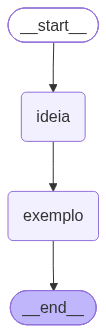

In [62]:
class TravelState(TypedDict, total=False):
    ideia: str
    exemplo: str

def node_ideia(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content="Gere uma ideia de exemplo prático (1 frase) para ensinar conceitos moeda quântica.")
    ])
    return {"ideia": resp.content.strip()}

def node_exemplo(state: TravelState) -> TravelState:
    resp = llm.invoke([
        SystemMessage(content="Responda em PT-BR, curto e claro."),
        HumanMessage(content=(
            "Crie um exemplo prático de sala de aula usando a ideia abaixo.\n"
            f"IDEIA: {state.get('ideia','')}\n"
            "Formato: 6-10 linhas, com bullets."
        ))
    ])
    return {"exemplo": resp.content}

travel_builder = StateGraph(TravelState)
travel_builder.add_node("ideia", node_ideia)
travel_builder.add_node("exemplo", node_exemplo)
travel_builder.add_edge(START, "ideia")
travel_builder.add_edge("ideia", "exemplo")
travel_builder.add_edge("exemplo", END)

travel_checkpointer = MemorySaver()
travel_graph = travel_builder.compile(checkpointer=travel_checkpointer)
travel_graph

In [63]:
t_cfg = {"configurable": {"thread_id": "travel-01"}}

original = travel_graph.invoke({}, config=t_cfg)

print("IDEIA:", original["ideia"])
print("EXEMPLO:\n", original["exemplo"])

IDEIA: Lance uma moeda virtual que, ao ser "virada", colapsa instantaneamente para cara ou coroa apenas quando o usuário a observa no aplicativo.
EXEMPLO:
 - **Objetivo:** Demonstrar conceitos de superposição e colapso de estado da mecânica quântica.  
- **Ferramenta:** App de realidade aumentada que exibe uma moeda virtual em superposição (girando).  
- **Procedimento:** Cada aluno abre o app e vê a moeda “flutuando” sem definição de cara ou coroa.  
- **Ação:** Ao tocar na tela (observar), a moeda colapsa instantaneamente para cara ou coroa.  
- **Registro:** O aluno anota o resultado e o instante da observação.  
- **Discussão:** Comparar a aleatoriedade do colapso com lançamentos de moedas reais e discutir a influência do observador.  
- **Avaliação:** Perguntas curtas sobre por que a moeda só define um lado ao ser observada.


In [68]:
history = list(travel_graph.get_state_history(t_cfg))
print("Quantidade de checkpoints:", len(history))

for i, st in enumerate(history[:6]):
    checkpoint_id = st.config["configurable"].get("checkpoint_id")
    print(f"{i}: next={st.next} | checkpoint_id={checkpoint_id} | keys={list(st.values.keys())}")

Quantidade de checkpoints: 12
0: next=() | checkpoint_id=1f1d512e-98dd-6e94-8004-bc9319940d3d | keys=['ideia', 'exemplo']
1: next=('exemplo',) | checkpoint_id=1f1d512e-914a-64c5-8003-ddd359f6ca8c | keys=['ideia']
2: next=() | checkpoint_id=1f1d512e-9147-6d4a-8004-08481112c723 | keys=['ideia', 'exemplo']
3: next=('exemplo',) | checkpoint_id=1f1d512e-8805-6bf5-8003-c75282068f62 | keys=['ideia']
4: next=() | checkpoint_id=1f1d5124-8f47-699c-8003-353ca9f21bbb | keys=['ideia', 'exemplo']
5: next=('exemplo',) | checkpoint_id=1f1d5124-867a-68f4-8002-4c1b894a0076 | keys=['ideia']


In [69]:
selected = next(
    st for st in history
    if st.next == ("exemplo",)
)

print("Checkpoint de origem:", selected.config["configurable"]["checkpoint_id"])

# Fork 1: atendimento de dúvidas.
config_fork1 = travel_graph.update_state(
    selected.config,
    values={
        "ideia": "Criar um chatbot que responde dúvidas do aluno sobre Python."
    },
)

fork1 = travel_graph.invoke(None, config=config_fork1)

# Fork 2: quiz adaptativo, partindo do mesmo checkpoint.
config_fork2 = travel_graph.update_state(
    selected.config,
    values={
        "ideia": "Criar um quiz que ajusta a dificuldade conforme os acertos do aluno."
    },
)

fork2 = travel_graph.invoke(None, config=config_fork2)



print("\n--- FORK 1 ---")
print("IDEIA:", fork1["ideia"])
print("EXEMPLO:\n", fork1["exemplo"])

print("\n--- FORK 2 ---")
print("IDEIA:", fork2["ideia"])
print("EXEMPLO:\n", fork2["exemplo"])

print("\n--- COMPARAÇÃO ---")
print("As ideias são iguais?", fork1["ideia"] == fork2["ideia"])
print("Os exemplos são iguais?", fork1["exemplo"] == fork2["exemplo"])

Checkpoint de origem: 1f1d512e-914a-64c5-8003-ddd359f6ca8c

--- FORK 1 ---
IDEIA: Criar um chatbot que responde dúvidas do aluno sobre Python.
EXEMPLO:
 - **Objetivo:** Usar um chatbot para responder dúvidas de alunos sobre sintaxe e conceitos básicos de Python.  
- **Ferramenta:** Bot criado no Dialogflow integrado ao Google Classroom.  
- **Atividade:** Cada aluno envia, via chat, uma pergunta (ex.: “Como faço um laço `for`?”).  
- **Resposta do bot:** Mensagem automática com explicação curta + exemplo de código.  
- **Feedback:** O bot solicita ao aluno que teste o exemplo e informe se funcionou.  
- **Registro:** As interações são salvas em planilha para o professor analisar pontos de dificuldade.  
- **Avaliação:** No final da aula, o professor revisa as dúvidas mais frequentes e ajusta o conteúdo.

--- FORK 2 ---
IDEIA: Criar um quiz que ajusta a dificuldade conforme os acertos do aluno.
EXEMPLO:
 - **Objetivo:** Avaliar a compreensão de álgebra e adaptar a dificuldade conforme o

In [5]:
from typing import Annotated, List, TypedDict
import operator
from langgraph.graph import StateGraph, START, END

class ParallelState(TypedDict, total=False):
    tema: str
    blocos: Annotated[List[str], operator.add]


def gerar_erro_comum(state: ParallelState):
    return {
        "blocos": [
            f"Erro comum em {state['tema']}: vários nós paralelos "
            "atualizarem 'blocos' sem definir um reducer, causando "
            "conflito nas atualizações."
        ]
    }


builder2 = StateGraph(ParallelState)
builder2.add_node("inicio", inicio)
builder2.add_node("gerar_exemplo", gerar_exemplo)
builder2.add_node("gerar_analogia", gerar_analogia)
builder2.add_node("gerar_erro_comum", gerar_erro_comum)  # novo
builder2.add_node("juntar", juntar)

builder2.add_edge(START, "inicio")
builder2.add_edge("inicio", "gerar_exemplo")
builder2.add_edge("inicio", "gerar_analogia")
builder2.add_edge("inicio", "gerar_erro_comum")  # novo
builder2.add_edge("gerar_exemplo", "juntar")
builder2.add_edge("gerar_analogia", "juntar")
builder2.add_edge("gerar_erro_comum", "juntar")  # novo
builder2.add_edge("juntar", END)

g_parallel = builder2.compile()
out = g_parallel.invoke({"tema": "paralelização e reducers no LangGraph"})

print("Blocos acumulados:")
for b in out.get("blocos", []):
    print("-", b)
g_parallel

NameError: name 'inicio' is not defined